In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install vaderSentiment

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 3.3 MB/s eta 0:00:00


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import yfinance as yf
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import warnings
warnings.filterwarnings('ignore')


In [4]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

In [19]:
# Check the first few rows of each dataframe to confirm column names
print(financial_news_sentiment.head())
print(reddit_financial_sentiment.head())
print(yahoo_finance_stock_prices.head())
print(stock_market_news.head())


    neutral  \
0   neutral   
1  negative   
2  positive   
3  positive   
4  positive   

  According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .  
0  Technopolis plans to develop in stages an area...                                                                               
1  The international electronic industry company ...                                                                               
2  With the new production plant the company woul...                                                                               
3  According to the company 's updated strategy f...                                                                               
4  FINANCING OF ASPOCOMP 'S GROWTH Aspocomp is ag...                                                                               
                                               title  score      id  \
0  What is the Best Cold Wallet? (DECEMBER 202

In [24]:
# Convert 'timestamp' to 'date'
reddit_financial_sentiment['date'] = pd.to_datetime(reddit_financial_sentiment['timestamp']).dt.date


In [26]:
print(financial_news_sentiment.columns)


Index(['neutral', 'According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .'], dtype='object')


In [35]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Load datasets with appropriate encoding and handling Excel file
try:
    financial_news_sentiment = pd.read_csv('/content/drive/MyDrive/Stock Market/Financial News/all-data.csv', encoding='ISO-8859-1')
except Exception as e:
    print(f"Error loading financial news sentiment data: {e}")

try:
    reddit_financial_sentiment = pd.read_csv('/content/drive/MyDrive/Stock Market/Reddit/CryptoCurrency.csv', encoding='ISO-8859-1')
except Exception as e:
    print(f"Error loading Reddit financial sentiment data: {e}")

try:
    yahoo_finance_stock_prices = pd.read_excel('/content/drive/MyDrive/Stock Market/yahoo/yahoo_data.xlsx')
except Exception as e:
    print(f"Error loading Yahoo Finance stock prices data: {e}")

# Inspect column names
print("Financial News Sentiment Columns:", financial_news_sentiment.columns)
print("Reddit Financial Sentiment Columns:", reddit_financial_sentiment.columns)
print("Yahoo Finance Stock Prices Columns:", yahoo_finance_stock_prices.columns)

# For financial news sentiment, assuming 'date' or equivalent column needs to be created
# Create a placeholder date column if necessary
if 'timestamp' not in financial_news_sentiment.columns:
    financial_news_sentiment['timestamp'] = pd.to_datetime('2021-01-01')  # Placeholder, replace with actual logic if possible

# Convert the timestamp to a date format for financial news sentiment and reddit financial sentiment
financial_news_sentiment['date'] = pd.to_datetime(financial_news_sentiment['timestamp']).dt.date
reddit_financial_sentiment['date'] = pd.to_datetime(reddit_financial_sentiment['timestamp']).dt.date

# Adjust Yahoo Finance stock prices date column
yahoo_finance_stock_prices.rename(columns={'Date': 'date'}, inplace=True)
yahoo_finance_stock_prices['date'] = pd.to_datetime(yahoo_finance_stock_prices['date']).dt.date

# Convert sentiment values to numeric, assuming 'neutral' column needs to be converted
try:
    financial_news_sentiment['neutral'] = financial_news_sentiment['neutral'].replace(
        {'neutral': 0, 'positive': 1, 'negative': -1}).astype(float)
except Exception as e:
    print(f"Error converting sentiment values: {e}")

# Aggregate sentiment data by date
financial_news_sentiment_daily = financial_news_sentiment.groupby('date').agg({'neutral': 'mean'}).reset_index()
reddit_financial_sentiment_daily = reddit_financial_sentiment.groupby('date').agg({'score': 'mean'}).reset_index()

# Prepare stock data for AMZN (assuming 'symbol' column exists)
# If symbol column doesn't exist, skip this filtering
if 'symbol' in yahoo_finance_stock_prices.columns:
    amzn_stock_data = yahoo_finance_stock_prices[yahoo_finance_stock_prices['symbol'] == 'AMZN']
else:
    amzn_stock_data = yahoo_finance_stock_prices

# Select relevant columns
amzn_stock_data = amzn_stock_data[['date', 'Open', 'High', 'Low', 'Close*', 'Volume']]

# Merge sentiment data with stock data
merged_data = amzn_stock_data.merge(financial_news_sentiment_daily, on='date', how='left')
merged_data = merged_data.merge(reddit_financial_sentiment_daily, on='date', how='left', suffixes=('_news', '_reddit'))

# Fill missing sentiment values with 0
merged_data['neutral'].fillna(0, inplace=True)
merged_data['score'].fillna(0, inplace=True)

# Define features and target
features = ['Open', 'High', 'Low', 'Volume', 'neutral', 'score']
target = 'Close*'

# Split data into training and testing sets
X = merged_data[features]
y = merged_data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on test data
y_pred = rf_model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
print(f'MAE: {mae}, MSE: {mse}')

# Perform cross-validation
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='neg_mean_absolute_error')
print(f'Cross-Validation MAE: {-cv_scores.mean()}')


Financial News Sentiment Columns: Index(['neutral', 'According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .'], dtype='object')
Reddit Financial Sentiment Columns: Index(['title', 'score', 'id', 'url', 'comms_num', 'created', 'body',
       'timestamp'],
      dtype='object')
Yahoo Finance Stock Prices Columns: Index(['Date', 'Open', 'High', 'Low', 'Close*', 'Adj Close**', 'Volume'], dtype='object')
MAE: 122.72218134920583, MSE: 32644.373536805917
Cross-Validation MAE: 246.49619510403318


In [36]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Assuming 'merged_data' is already prepared as per the previous steps

# Define features and target
features = ['Open', 'High', 'Low', 'Volume', 'neutral', 'score']
target = 'Close*'

# Split data into training and testing sets
X = merged_data[features]
y = merged_data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train a Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict on test data
y_pred = rf_model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
print(f'MAE: {mae}, MSE: {mse}')

# Perform cross-validation
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='neg_mean_absolute_error')
cv_mae = -cv_scores.mean()
print(f'Cross-Validation MAE: {cv_mae}')

# Optionally, you can also print individual cross-validation scores for more detail
print('Individual CV Scores:', -cv_scores)

# Optionally, you can save the model for future use
# import joblib
# joblib.dump(rf_model, 'rf_model.pkl')


MAE: 122.72218134920583, MSE: 32644.373536805917
Cross-Validation MAE: 246.49619510403318
Individual CV Scores: [149.89222659 683.10550119 116.94541667 193.95617012  88.58166096]


In [38]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import cross_val_score

# Make predictions on the test set
predictions = rf_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)

print(f'Mean Absolute Error (MAE): {mae:.2f}')
print(f'Mean Squared Error (MSE): {mse:.2f}')
print(f'Root Mean Squared Error (RMSE): {rmse:.2f}')

# Cross-validation
cv_scores = cross_val_score(rf_model, X, y, cv=5, scoring='neg_mean_squared_error')
cv_rmse_scores = np.sqrt(-cv_scores)

print(f'Cross-Validation RMSE: {cv_rmse_scores.mean():.2f} +/- {cv_rmse_scores.std():.2f}')


Mean Absolute Error (MAE): 122.72
Mean Squared Error (MSE): 32644.37
Root Mean Squared Error (RMSE): 180.68
Cross-Validation RMSE: 373.51 +/- 298.39


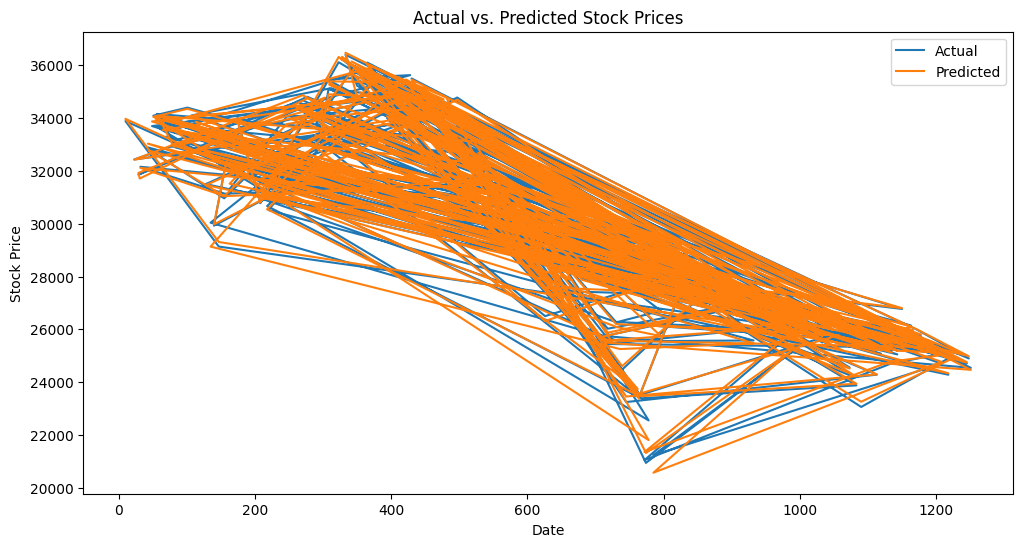

In [39]:
import matplotlib.pyplot as plt

# Example code to visualize predictions vs. actual
plt.figure(figsize=(12, 6))
plt.plot(y_test.index, y_test, label='Actual')
plt.plot(y_test.index, predictions, label='Predicted')
plt.xlabel('Date')
plt.ylabel('Stock Price')
plt.title('Actual vs. Predicted Stock Prices')
plt.legend()
plt.show()


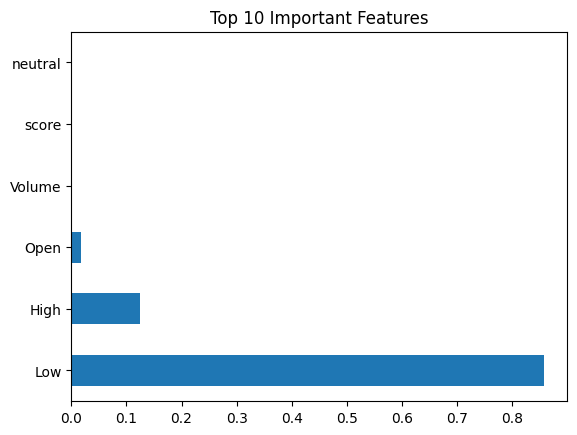

In [40]:
# Example code to plot feature importances (for RandomForestRegressor rf_model)
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
feature_importances.nlargest(10).plot(kind='barh')
plt.title('Top 10 Important Features')
plt.show()


In [43]:
!pip install ta
import pandas as pd
import numpy as np
import ta  # Technical Analysis library

# Assuming you have loaded Yahoo Finance stock prices into yahoo_finance_stock_prices DataFrame

# Check the available columns in your DataFrame
print(yahoo_finance_stock_prices.columns)

# If 'Date' is not present, adjust accordingly (e.g., if it's 'date')
# Convert 'date' column to datetime (adjust the column name if needed)
yahoo_finance_stock_prices['date'] = pd.to_datetime(yahoo_finance_stock_prices['date'])

# Sort DataFrame by date if not already sorted
yahoo_finance_stock_prices = yahoo_finance_stock_prices.sort_values('date')

# Calculate technical indicators using TA library (e.g., Moving Average, RSI)
yahoo_finance_stock_prices['SMA_20'] = ta.trend.sma_indicator(yahoo_finance_stock_prices['Close*'], window=20)
yahoo_finance_stock_prices['RSI_14'] = ta.momentum.rsi(yahoo_finance_stock_prices['Close*'], window=14)

# Check the new columns
print(yahoo_finance_stock_prices[['date', 'Close*', 'SMA_20', 'RSI_14']].head()) # Adjust the column name here as well

Index(['date', 'Open', 'High', 'Low', 'Close*', 'Adj Close**', 'Volume'], dtype='object')
           date    Close*  SMA_20  RSI_14
1257 2018-05-01  24099.05     NaN     NaN
1256 2018-05-02  23924.98     NaN     NaN
1255 2018-05-03  23930.15     NaN     NaN
1254 2018-05-04  24262.51     NaN     NaN
1253 2018-05-07  24357.32     NaN     NaN


In [45]:
!pip install nltk
import nltk
nltk.download('punkt')

from nltk import tokenize
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# Example text for aspect-based sentiment analysis
text = "The new product is great, but customer service needs improvement."

# Tokenize the text into sentences
sentences = tokenize.sent_tokenize(text)

# Initialize sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

# Calculate sentiment for each sentence
sentiment_scores = []
for sentence in sentences:
    vs = analyzer.polarity_scores(sentence)
    sentiment_scores.append(vs)

# Aggregate sentiment scores
overall_sentiment = {
    'compound': np.mean([s['compound'] for s in sentiment_scores]),
    'positive': np.mean([s['pos'] for s in sentiment_scores]),
    'negative': np.mean([s['neg'] for s in sentiment_scores]),
    'neutral': np.mean([s['neu'] for s in sentiment_scores])
}

print("Overall Sentiment Scores:", overall_sentiment)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


Overall Sentiment Scores: {'compound': 0.7615, 'positive': 0.45, 'negative': 0.0, 'neutral': 0.55}


In [46]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Assuming you have prepared your feature matrix X and target vector y

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize Random Forest Regressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Fit the model
rf_model.fit(X_train, y_train)

# Predict on test set
y_pred = rf_model.predict(X_test)

# Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)


Mean Squared Error: 32644.373536805917


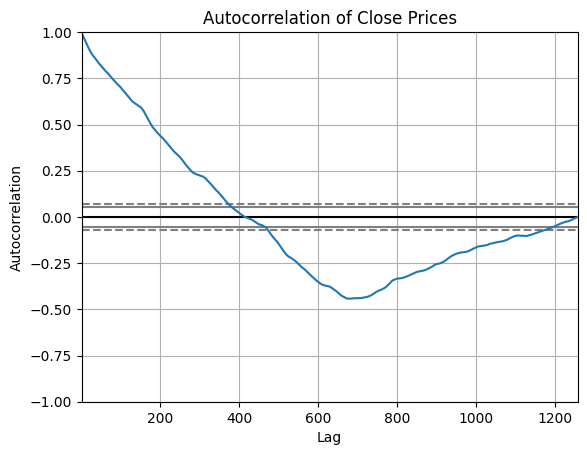

In [47]:
from pandas.plotting import autocorrelation_plot

# Assuming 'Close*' column is already loaded into yahoo_finance_stock_prices DataFrame

# Plot autocorrelation
autocorrelation_plot(yahoo_finance_stock_prices['Close*'])
plt.title('Autocorrelation of Close Prices')
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.show()


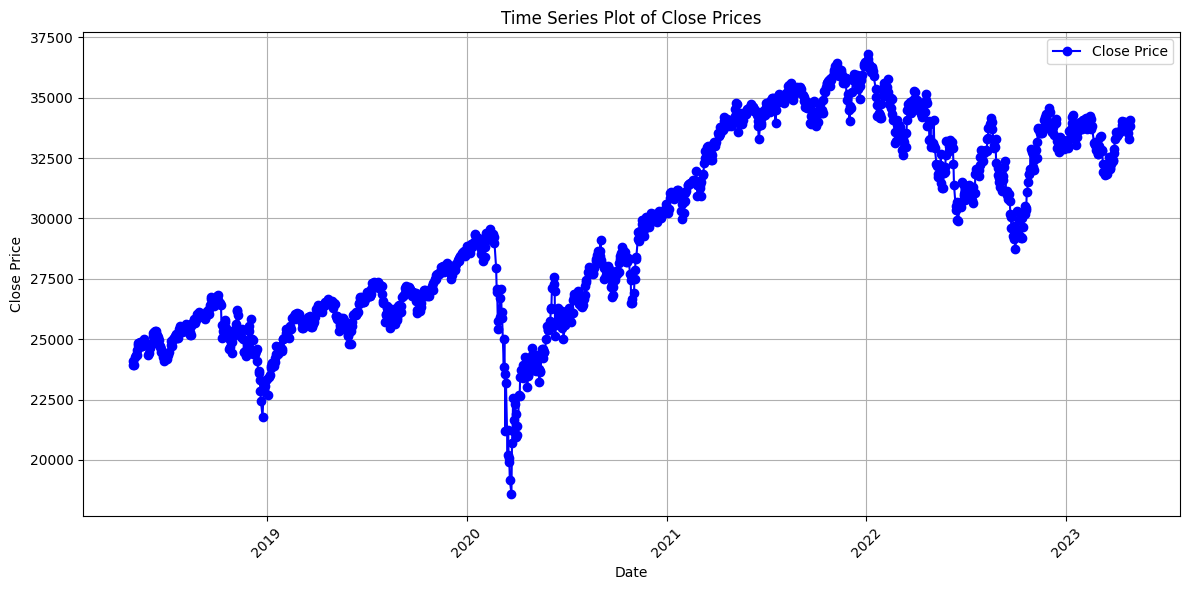

In [49]:
import matplotlib.pyplot as plt

# Assuming 'Date' and 'Close*' columns are already loaded into yahoo_finance_stock_prices DataFrame

plt.figure(figsize=(12, 6))
# Use 'date' instead of 'Date' for the x-axis
plt.plot(yahoo_finance_stock_prices['date'], yahoo_finance_stock_prices['Close*'], marker='o', linestyle='-', color='b', label='Close Price')
plt.title('Time Series Plot of Close Prices')
plt.xlabel('Date')
plt.ylabel('Close Price')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['neutral',
       'According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .',
       'timestamp', 'date'],
      dtype='object')


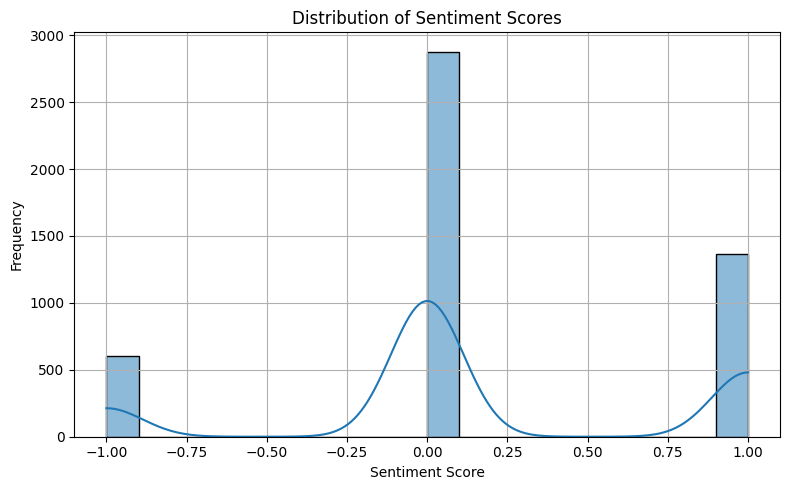

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming 'sentiment' column is already loaded into financial_news_sentiment DataFrame
# Verify the column names and correct if needed
print(financial_news_sentiment.columns)

# If 'sentiment' is not present, use the correct column name
plt.figure(figsize=(8, 5))
# Replace 'sentiment' with the actual name of the sentiment column from the output above
sns.histplot(financial_news_sentiment['neutral'], bins=20, kde=True) # Replace 'sentiment' with the correct column name
plt.title('Distribution of Sentiment Scores')
plt.xlabel('Sentiment Score')
plt.ylabel('Frequency')
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['neutral',
       'According to Gran , the company has no plans to move all production to Russia , although that is where the company is growing .',
       'timestamp', 'date'],
      dtype='object')


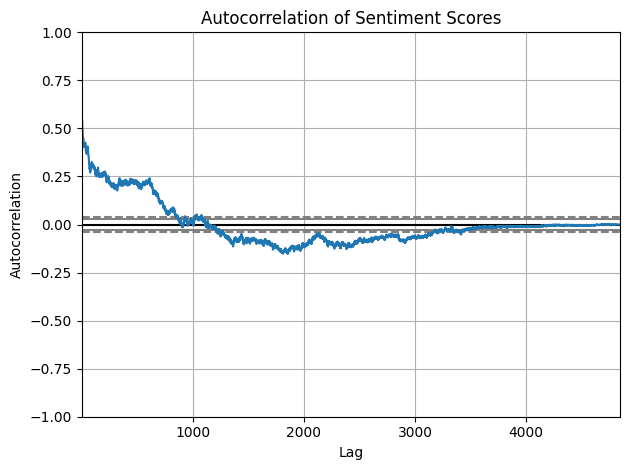

In [60]:
import pandas as pd
from pandas.plotting import autocorrelation_plot

# Assuming 'Date' and 'sentiment' columns are already loaded into financial_news_sentiment DataFrame

# Print the columns of the dataframe to check for the correct name
print(financial_news_sentiment.columns)

# Replace 'Date' with the actual date column name from the output above
financial_news_sentiment['date'] = pd.to_datetime(financial_news_sentiment['date']) # Replace 'Date' with the actual column name 'date'

# Sort DataFrame by date if not already sorted
financial_news_sentiment = financial_news_sentiment.sort_values('date') # Replace 'Date' with the actual column name 'date'

# Plot autocorrelation
# Replace 'sentiment' with the actual sentiment column name if needed
autocorrelation_plot(financial_news_sentiment['neutral']) # Replace 'neutral' with the actual sentiment column name if needed
plt.title('Autocorrelation of Sentiment Scores')
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.grid(True)
plt.tight_layout()
plt.show()

Index(['date', 'neutral', 'score'], dtype='object')


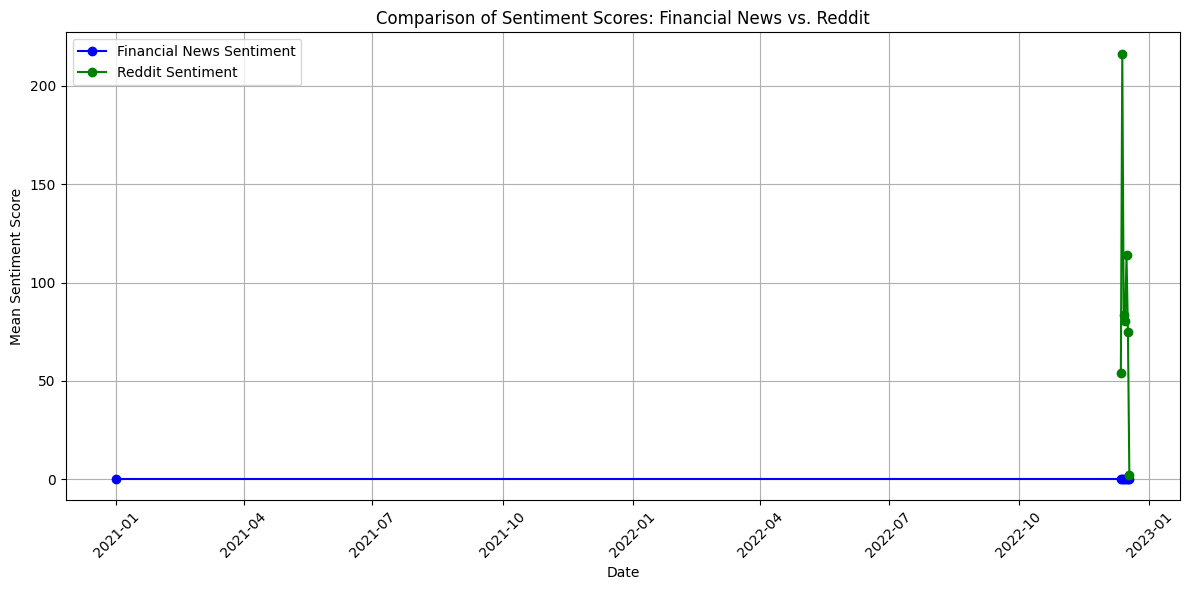

In [77]:
merged_data = pd.merge(financial_news_sentiment_daily, reddit_financial_sentiment_daily, on='date', suffixes=('_news', '_reddit'), how='outer')

# Check the column names of the merged DataFrame
print(merged_data.columns)

# Fill missing values (NaN) with a suitable method (e.g., forward fill)
merged_data.fillna(method='ffill', inplace=True)

# Plot comparison graph
plt.figure(figsize=(12, 6))

# Plot line for financial news sentiment
# Use 'date' and the correct column name for the financial news sentiment (check the output of the previous print statement)
plt.plot(merged_data['date'], merged_data['neutral'], marker='o', linestyle='-', color='b', label='Financial News Sentiment') # Use 'neutral' instead of 'neutral_news'

# Plot line for Reddit sentiment
plt.plot(merged_data['date'], merged_data['score'], marker='o', linestyle='-', color='g', label='Reddit Sentiment') # Use 'score' instead of 'score_reddit'

plt.title('Comparison of Sentiment Scores: Financial News vs. Reddit')
plt.xlabel('Date')
plt.ylabel('Mean Sentiment Score')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()